# hiNiche: multi-slice mouse brain Visium HD analysis

Joint multi-scale (spot / cell / niche) cell-type deconvolution and niche discovery across several Visium HD slices.

> **Environment:** run this notebook in the main **`hiNiche`** environment (`environment.yml`).

**Workflow.** Preprocessing is done slice by slice with `preprocess_multislice.py` (all preprocessing parameters are set at the top of that script), so the slices are never loaded together:

```bash
python preprocess_multislice.py --mode genes                  # shared genes + reference
python preprocess_multislice.py --mode slice --slice-idx 0    # one job per slice
python preprocess_multislice.py --mode slice --slice-idx 1
python preprocess_multislice.py --mode slice --slice-idx 2
python preprocess_multislice.py --mode collect                # meta.pkl for training
```

This notebook then trains all slices jointly and analyzes the results.

## 1. Setup and imports

In [1]:
import os
import sys
# cupy (used by rapids_singlecell) compiles GPU kernels at runtime and needs the CUDA headers shipped inside the conda environment
os.environ.setdefault("CUDA_PATH", os.path.join(sys.prefix, "targets", "x86_64-linux"))

# --- Project modules ---
import config
import utils
from train import run_train_seq

# --- Standard library ---
import pickle
import warnings

# --- Data handling ---
import numpy as np
import pandas as pd
import anndata as ad

# --- Deep learning ---
import torch
import torch.nn.functional as F

# --- Clustering ---
import rapids_singlecell as rsc     # GPU-accelerated neighbors / Leiden / UMAP
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

# --- Plotting ---
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

%load_ext autoreload
%autoreload 2

warnings.filterwarnings("ignore")

/hpc/home/wz220/miniconda3/envs/hiNiche/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Parameter configuration

Preprocessing parameters are set in `preprocess_multislice.py` and stored in `meta.pkl`; the model path, training hyperparameters and analysis settings are set here.

In [9]:
SAMPLE = "Mousebrain_HD_multi_slices"

# Output directory of preprocess_multislice.py (OUT_DIR): meta.pkl, adata_slice{i}.h5ad
PREPROCESS_DIR = f"DATA/{SAMPLE}/preprocessed"

#Model save path (if the file exists, the model is loaded and training is skipped)
MODEL_SAVE_DIR = f"DATA/{SAMPLE}/checkpoint.pt"

# Cell-type color map defined in config.py
celltype_color = getattr(config, "colormap_mouse_brain_41")
umap_color = getattr(config, "umap_100")
# Slice / batch colors: blue -> pink (with 3 slices: 0.12 / 0.5 / 0.88 of the gradient)
bluepink = LinearSegmentedColormap.from_list(
    "bluepink", ["#2b3fb0", "#6f8be0", "#b6a3d8", "#e58bbf", "#ff6fae"])

# Model / training hyperparameters
lr          = 0.005
num_epochs  = 30
edge_drop   = 0.5
member_drop = 0.5
neg_samples = 5
tau         = 1
alpha       = 1
beta        = 1  
seed        = 42

# Niche clustering / merging
emb_k        = 50      # neighbors of the KNN graph on embeddings (Leiden / UMAP)
resolution   = 0.5     # Leiden resolution; higher -> more clusters
merge_thresh = 0.05    # cosine distance below which niche clusters with similar composition are merged

device = "cuda:0"

## 3. Load preprocessed slices

`meta.pkl` holds the training inputs (unit numbers and patch directory of each slice, reference matrix) and the preprocessing parameters. For each slice only the spot coordinates and the spot → cell matrix are loaded from `adata_slice{i}.h5ad`; the expression matrix stays on disk (`backed="r"`).

In [3]:
with open(os.path.join(PREPROCESS_DIR, "meta.pkl"), "rb") as f:
    meta = pickle.load(f)

SLICES     = meta["slice_names"]          # training slice index i <-> SLICES[i]
n_slice    = len(SLICES)
slice_colors = [bluepink(v) for v in np.linspace(0.12, 0.88, n_slice)]   # one color per slice (all slice / batch plots)
P          = meta["params"]               # preprocessing parameters (for reference)
celltypes  = meta["celltypes"]
ref_matrix = meta["ref_matrix"]
active_niche_indices_list = meta["active_niche_indices_list"]

print(f"{n_slice} slices: {SLICES} | input genes {meta['in_dim']} | cell types {meta['hidden_dim']}")
for k, v in P.items():
    print(f"  {k:20s} = {v}")

# Per-slice spot coordinates and spot -> cell matrices
spatial_grid_list, spatial_pixel_list, S_s2c_list = [], [], []
for i, s in enumerate(SLICES):
    a = ad.read_h5ad(os.path.join(PREPROCESS_DIR, f"adata_slice{i}.h5ad"), backed="r")
    spatial_grid_list.append(np.asarray(a.obsm["spatial_grid"]))
    spatial_pixel_list.append(np.asarray(a.obsm["spatial_pixel"]))
    S_s2c_list.append(utils.sp_to_torch_sparse(a.obsm["S_s2c"]))
    a.file.close()

    # Consistency check with the cached mini-batches
    n = meta["sample_number_list"][i]
    assert S_s2c_list[i].shape == (n["spot"], n["cell"]), f"{s}: adata_slice{i}.h5ad does not match meta.pkl"
    print(f"[Log] {s}: {n['spot']} spots, {n['cell']} cells, {n['niche']} niches")

3 slices: ['slice1', 'slice2', 'slice3'] | input genes 4813 | cell types 41
  bg_threshold         = 50
  bg_rings             = 4
  max_spots_per_cell   = 100
  min_spots_per_cell   = 3
  Patch_size           = 512
  halo                 = 32
  graph_knn            = 12
  niche_knn            = 15
[Log] slice1: 7224615 spots, 71380 cells, 71380 niches
[Log] slice2: 6618476 spots, 73323 cells, 73323 niches
[Log] slice3: 5402710 spots, 51395 cells, 51395 niches


## 4. Joint multi-slice training

In [62]:
emb_all, slice_id = run_train_seq(meta["sample_number_list"],
                                  PATCH_LOC = meta["PATCH_LOC"],
                                  MODEL_SAVE_DIR = MODEL_SAVE_DIR,
                                  ref_matrix = ref_matrix,
                                  lr = lr,
                                  in_dim = meta["in_dim"],
                                  hidden_dim = meta["hidden_dim"],
                                  num_epochs = num_epochs,
                                  edge_drop = edge_drop,
                                  member_drop = member_drop,
                                  neg_samples = neg_samples,
                                  tau = tau,
                                  alpha = alpha,
                                  beta = beta,
                                  seed = seed,
                                  device = device)
# emb_all[level]: embeddings of all slices concatenated; slice_id[level]: slice index of each row

Epoch 30: 100%|██████████| 101/101 [00:20<00:00,  4.85it/s, cl=5.0238, nll=436.6078, entp=-6.0018]


Training finished!
Model saved to DATA/Mousebrain_HD_multi_slices/checkpoint.pt


generating embeddings (slice 2)...: 100%|██████████| 31/31 [00:05<00:00,  5.56it/s]


## 5. Re-assign unmapped spots

In [5]:
# Re-assign unmapped (background) spots to nearby cells using spot embeddings, slice by slice
S_s2c_updated_list = []
for b, s in enumerate(SLICES):
    spot_embs = emb_all["spot"][slice_id["spot"] == b].detach().cpu().numpy()
    new_assignments = utils.reassign_unmapped_spots(
        S_s2c_list[b],
        spatial_grid_list[b],                # grid coordinates of this slice, 1 unit = 1 spot
        spot_embs,
        algorithm="fixed_boundary",
        fixed_distance=2,
    )
    print(f"[Log] {s}: {len(new_assignments)} background spots re-assigned")
    S_s2c_updated_list.append(utils.update_S(S_s2c_list[b], new_assignments))

Total unassigned spots: 6616482


Assigning spots (boundary): 100%|██████████| 6616482/6616482 [01:35<00:00, 69479.98it/s]


[Log] slice1: 1521112 background spots re-assigned
Total unassigned spots: 5724089


Assigning spots (boundary): 100%|██████████| 5724089/5724089 [01:28<00:00, 64612.07it/s]


[Log] slice2: 1687786 background spots re-assigned
Total unassigned spots: 4775101


Assigning spots (boundary): 100%|██████████| 4775101/4775101 [01:07<00:00, 70640.55it/s]


[Log] slice3: 1185632 background spots re-assigned


## 6. Visualization

### 6.1 Spot- and cell-level cell-type maps

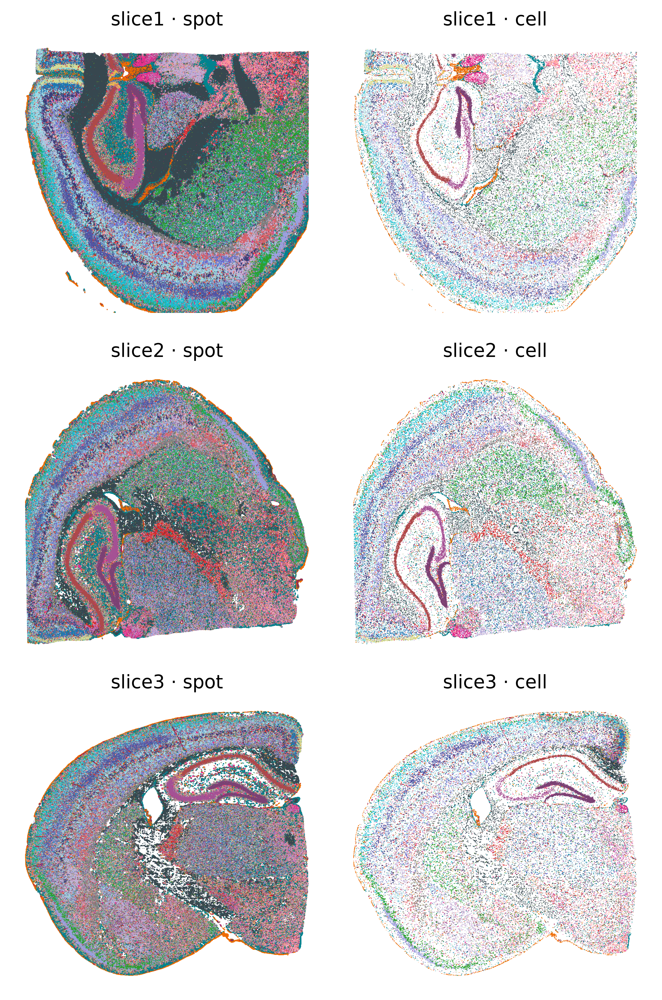

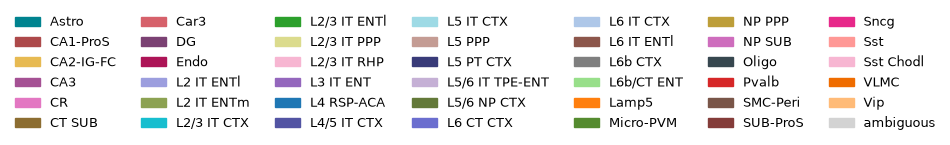

In [64]:
def type_labels(prob_max, prob_idx):
    """Cell-type label per row: "filtered" (no cell), "ambiguous" (max prob < 0.1) or the argmax type."""
    labels = []
    for p_, i_ in zip(prob_max, prob_idx):
        if i_ == -1:
            labels.append("filtered")
        elif p_ < 0.1:
            labels.append("ambiguous")
        else:
            labels.append(celltypes[i_])
    return labels

keys = ["spot", "cell"]
fig, axes = plt.subplots(n_slice, 2, figsize=(6, 3 * n_slice), dpi=600, squeeze=False)
labels_all_list = []
for b, s in enumerate(SLICES):
    x_raw, y_raw = spatial_pixel_list[b][:, 0], spatial_pixel_list[b][:, 1]
    S = S_s2c_updated_list[b].coalesce()

    labels_all = {}
    for ci, check in enumerate(keys):
        prob = F.softmax(emb_all[check][slice_id[check] == b], dim=1)   # embeddings of this slice
        max_prob_raw, max_idx_raw = torch.max(prob, dim=1)

        if check == "cell":
            # Broadcast each cell's prediction to its spots (spot -> cell mapping)
            rows, cols = S.indices()[0], S.indices()[1]
            spot2target = torch.full((S.size(0),), -1, dtype=torch.long, device=S.device)
            spot2target[rows] = cols
            max_idx  = torch.where(spot2target >= 0, max_idx_raw[spot2target],  torch.tensor(-1, device=S.device))
            max_prob = torch.where(spot2target >= 0, max_prob_raw[spot2target], torch.tensor(0.0, device=S.device))
        else:
            max_prob, max_idx = max_prob_raw, max_idx_raw

        labels_all[check] = type_labels(max_prob.cpu().numpy(), max_idx.cpu().numpy())
        ax = axes[b][ci]
        ax.scatter(x_raw, y_raw, c=[celltype_color[n] for n in labels_all[check]], s=0.5, marker='.', linewidths=0)
        ax.set_title(f"{s} · {check}")
        ax.invert_yaxis(); ax.axis("off")
    labels_all_list.append(labels_all)

plt.tight_layout()
plt.show()

# --- Legend (shared by all slices) ---
present = sorted({l for la in labels_all_list for l in la["spot"]})
handles = [mpatches.Patch(color=celltype_color.get(c, "#cccccc"), label=c) for c in present]
figL, axL = plt.subplots(figsize=(11, 0.6)); axL.axis("off")
axL.legend(handles=handles, ncol=7, frameon=False, loc="center", fontsize=9)
plt.show()

### 6.2 Joint niche clustering across slices (UMAP)

Leiden clustering of the niche embeddings of all slices together, so niche labels are shared across slices.

niche: 25 clusters


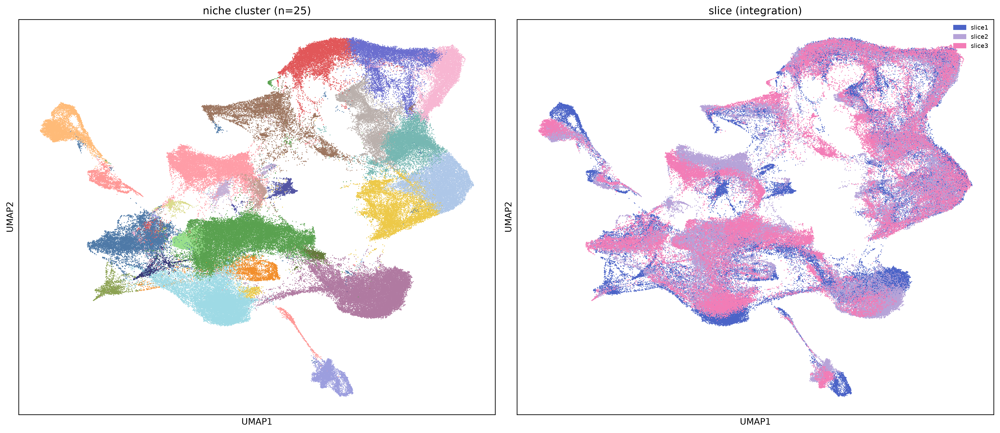

In [ ]:
# --- Cluster niche embeddings of all slices (Leiden) + UMAP, sharing one neighbor graph ---
adata_niche = ad.AnnData(emb_all["niche"].detach().cpu().numpy().astype(np.float32))
rsc.pp.neighbors(adata_niche, use_rep="X", n_neighbors=emb_k)
rsc.tl.leiden(adata_niche, resolution=resolution, random_state=seed)
rsc.tl.umap(adata_niche, random_state=seed)
niche_label = adata_niche.obs["leiden"].astype(int).values
niche_umap  = adata_niche.obsm["X_umap"]
clusters_id = {"niche": niche_label}
sid_niche   = slice_id["niche"].numpy()
print(f"niche: {len(np.unique(niche_label))} clusters")

# --- Left: dominant cell type; middle: niche cluster; right: slice (integration check) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=300)
axes[0].scatter(niche_umap[:, 0], niche_umap[:, 1],
                c=[umap_color[f"Cluster_{v % 40}"] for v in niche_label], s=1, linewidths=0)
axes[0].set_title(f"niche cluster (n={len(np.unique(niche_label))})")

axes[1].scatter(niche_umap[:, 0], niche_umap[:, 1],
                c=[slice_colors[b] for b in sid_niche], s=1, linewidths=0)
axes[1].set_title("slice (integration)")
axes[1].legend(handles=[mpatches.Patch(color=slice_colors[b], label=s) for b, s in enumerate(SLICES)],
               fontsize=7, frameon=False, loc="upper right")

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")
plt.tight_layout()
plt.show()

### 6.3 Merge niches by cell-type composition

The composition of a niche cluster is the cell-type distribution of the niche centers (niche j of slice b is centered at cell `active_niche_indices_list[b][j]`).

25 niche clusters -> 25 merged


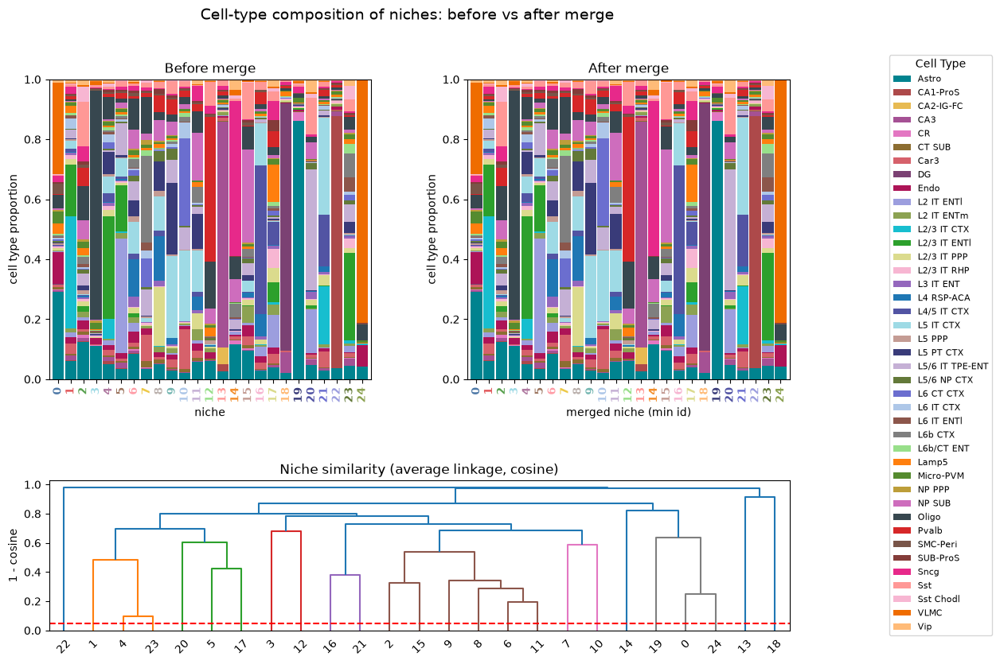

In [94]:
# ---- Cell type of each cell, then of each niche center (aligned with the rows of emb_all["niche"]) ----
cell_type = np.asarray(celltypes)[F.softmax(emb_all["cell"], dim=1).argmax(1).cpu().numpy()]
sid_cell = slice_id["cell"].numpy()
niche_center_type = np.concatenate([cell_type[sid_cell == b][np.asarray(active_niche_indices_list[b])]
                                    for b in range(n_slice)])

# ---- Composition table (before merge) ----
df_counts = pd.crosstab(np.asarray(clusters_id["niche"]), niche_center_type)

# ---- Hierarchical clustering + merge ----
comp = df_counts.div(df_counts.sum(1), axis=0)              # row-normalized composition
Z = linkage(comp.values, method="average", metric="cosine")
merged = fcluster(Z, t=merge_thresh, criterion="distance")
group_members = {}
for old, g in zip(comp.index, merged):
    group_members.setdefault(g, []).append(int(old))
old2new = {o: min(members) for members in group_members.values() for o in members}   # smallest id in each group becomes the new label

print(f"{len(comp)} niche clusters -> {len(set(old2new.values()))} merged")
for rep in sorted(set(old2new.values())):
    members = sorted(o for o, r in old2new.items() if r == rep)
    if len(members) > 1:
        print(f"  {members} -> {rep}")

niche_merged = np.array([old2new[l] for l in clusters_id["niche"]])
clusters_id["niche_merged"] = niche_merged

# ---- Composition tables as proportions (each bar stacks to 1) ----
dfm = pd.crosstab(niche_merged, niche_center_type)
comp_before = comp
comp_after  = dfm.div(dfm.sum(1), axis=0)

# ================= Layout: top row before/after merge, bottom row full-width dendrogram =================
fig = plt.figure(figsize=(12, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[2, 1], hspace=0.45, wspace=0.3)
ax_before = fig.add_subplot(gs[0, 0])
ax_after  = fig.add_subplot(gs[0, 1])
ax_dendro = fig.add_subplot(gs[1, :])

def stacked(ax, df, title, xlabel):
    """Stacked bar chart of cell-type proportions per niche; x tick labels colored by niche."""
    df.plot(kind="bar", stacked=True, ax=ax,
            color=[celltype_color[c] for c in df.columns], width=0.9, legend=False)
    for tick, nid in zip(ax.get_xticklabels(), df.index):
        tick.set_color(umap_color[f"Cluster_{nid % 40}"]); tick.set_fontweight("bold")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("cell type proportion")
    ax.set_ylim(0, 1)

stacked(ax_before, comp_before, "Before merge", "niche")
stacked(ax_after,  comp_after,  "After merge",  "merged niche (min id)")

handles, labels = ax_before.get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(1.0, 0.92), loc="upper left",
           title="Cell Type", prop={"size": 8})

dendrogram(Z, labels=comp.index.tolist(), ax=ax_dendro)
ax_dendro.axhline(merge_thresh, ls="--", c="r")
ax_dendro.set_ylabel("1 - cosine")
ax_dendro.set_title("Niche similarity (average linkage, cosine)")

fig.suptitle("Cell-type composition of niches: before vs after merge", fontsize=14)
plt.savefig("s.pdf")
plt.show()

### 6.4 Spatial maps per slice: cell types and niches before / after merge

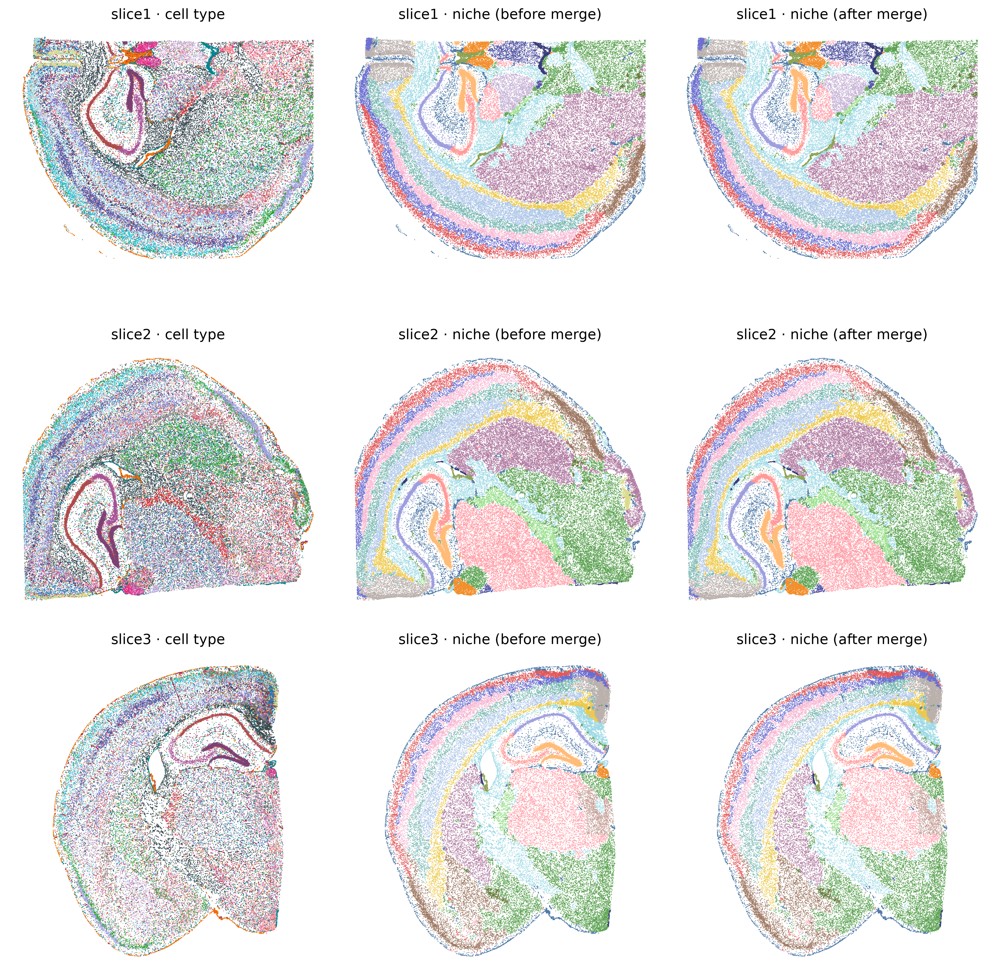

In [83]:
def col(labels):
    """Niche colors depend only on the label id, so colors stay consistent before / after merge."""
    return [umap_color[f"Cluster_{l % 40}"] for l in labels]

fig, axes = plt.subplots(n_slice, 3, figsize=(12, 4 * n_slice), dpi=300, squeeze=False)
for b, s in enumerate(SLICES):
    # Cell position = mean pixel coordinate of its spots (after re-assignment)
    S = S_s2c_updated_list[b].coalesce()
    s_rows, c_cols = S.indices()
    n_cell = S.size(1)
    spatial = torch.as_tensor(spatial_pixel_list[b], dtype=torch.float32)
    cell_pos = torch.zeros((n_cell, 2)).index_add_(0, c_cols, spatial[s_rows])
    cell_cnt = torch.zeros(n_cell).index_add_(0, c_cols, torch.ones_like(c_cols, dtype=torch.float32))
    cell_pos = (cell_pos / cell_cnt.clamp(min=1).unsqueeze(1)).numpy()

    # Niche labels of this slice mapped to their center cells (-1 = not a niche center)
    m = sid_niche == b
    active = np.asarray(active_niche_indices_list[b])
    cell_niche = np.full(n_cell, -1); cell_niche[active] = clusters_id["niche"][m]
    cell_niche_merged = np.full(n_cell, -1); cell_niche_merged[active] = clusters_id["niche_merged"][m]
    keep = (cell_cnt.numpy() > 0) & (cell_niche >= 0)
    ct_b = cell_type[sid_cell == b]

    axes[b][0].scatter(cell_pos[keep, 0], cell_pos[keep, 1], c=[celltype_color[c] for c in ct_b[keep]], s=0.5, linewidths=0)
    axes[b][0].set_title(f"{s} · cell type")
    axes[b][1].scatter(cell_pos[keep, 0], cell_pos[keep, 1], c=col(cell_niche[keep]), s=0.5, linewidths=0)
    axes[b][1].set_title(f"{s} · niche (before merge)")
    axes[b][2].scatter(cell_pos[keep, 0], cell_pos[keep, 1], c=col(cell_niche_merged[keep]), s=0.5, linewidths=0)
    axes[b][2].set_title(f"{s} · niche (after merge)")
    for ax in axes[b]:
        ax.invert_yaxis(); ax.set_aspect("equal"); ax.axis("off")

plt.tight_layout()
plt.show()

In [84]:
# --- Save niche cluster ids (before / after merge) and niche UMAP coordinates ---
# One row per niche (row order = rows of emb_all["niche"], all slices concatenated)
niche_out = pd.DataFrame({
    "slice":              np.asarray(SLICES)[sid_niche],
    "center_cell":        np.concatenate([np.asarray(active_niche_indices_list[b]) for b in range(n_slice)]),   # cell index within its slice
    "niche_before_merge": np.asarray(clusters_id["niche"]),
    "niche_after_merge":  np.asarray(clusters_id["niche_merged"]),
    "UMAP1":              niche_umap[:, 0],
    "UMAP2":              niche_umap[:, 1],
})
niche_out.index.name = "niche"
niche_out_path = f"DATA/{SAMPLE}/niche_clusters.csv"
niche_out.to_csv(niche_out_path)
print(f"[Log] saved {len(niche_out)} niches -> {niche_out_path}")
niche_out.head()

[Log] saved 196098 niches -> DATA/Mousebrain_HD_multi_slices/niche_clusters.csv


,slice,center_cell,niche_before_merge,niche_after_merge,UMAP1,UMAP2
niche,,,,,,
0,slice1,0,8,8,5.911800,8.817066
1,slice1,1,8,8,4.168363,10.898416
2,slice1,2,8,8,6.371096,7.060815
3,slice1,3,8,8,4.879289,10.453058
4,slice1,4,8,8,4.701824,10.299248


### 6.5 Cell embedding UMAP (integration check)

UMAP of the cell embeddings of all slices, colored by predicted cell type and by slice.

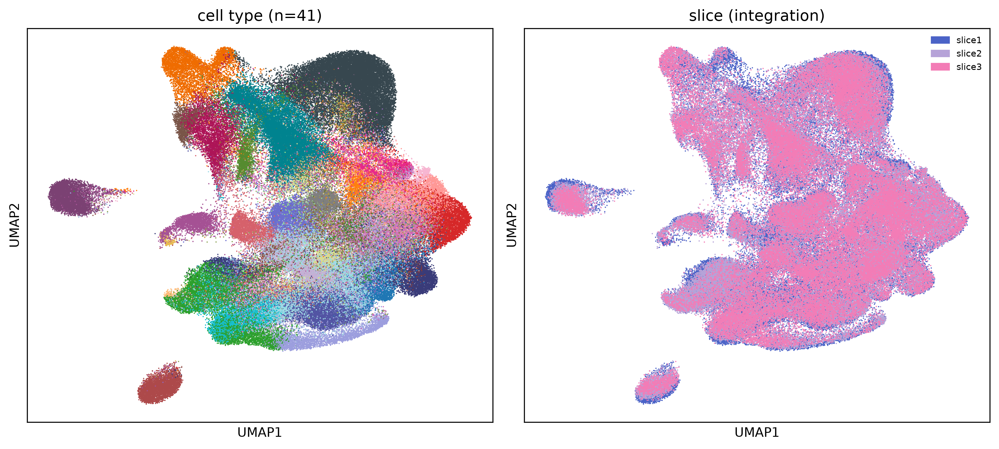

In [69]:
adata_cell = ad.AnnData(emb_all["cell"].detach().cpu().numpy().astype(np.float32))
rsc.pp.neighbors(adata_cell, use_rep="X", n_neighbors=emb_k)
rsc.tl.umap(adata_cell, random_state=seed)
cell_umap = adata_cell.obsm["X_umap"]

fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=300)
axes[0].scatter(cell_umap[:, 0], cell_umap[:, 1], c=[celltype_color.get(c, "#cccccc") for c in cell_type], s=1, linewidths=0)
axes[0].set_title(f"cell type (n={len(np.unique(cell_type))})")
axes[1].scatter(cell_umap[:, 0], cell_umap[:, 1], c=[slice_colors[b] for b in sid_cell], s=1, linewidths=0)
axes[1].set_title("slice (integration)")
axes[1].legend(handles=[mpatches.Patch(color=slice_colors[b], label=s) for b, s in enumerate(SLICES)],
               fontsize=7, frameon=False, loc="upper right")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")
plt.tight_layout()
plt.show()

## 7. ROI comparison: cell types vs. hiNiche niches

Regions of interest in full-resolution pixel coordinates, one per slice, each given as `[x_min, x_max, y_min, y_max]`. One figure is drawn for the cortex ROIs and one for the hippocampus ROIs.

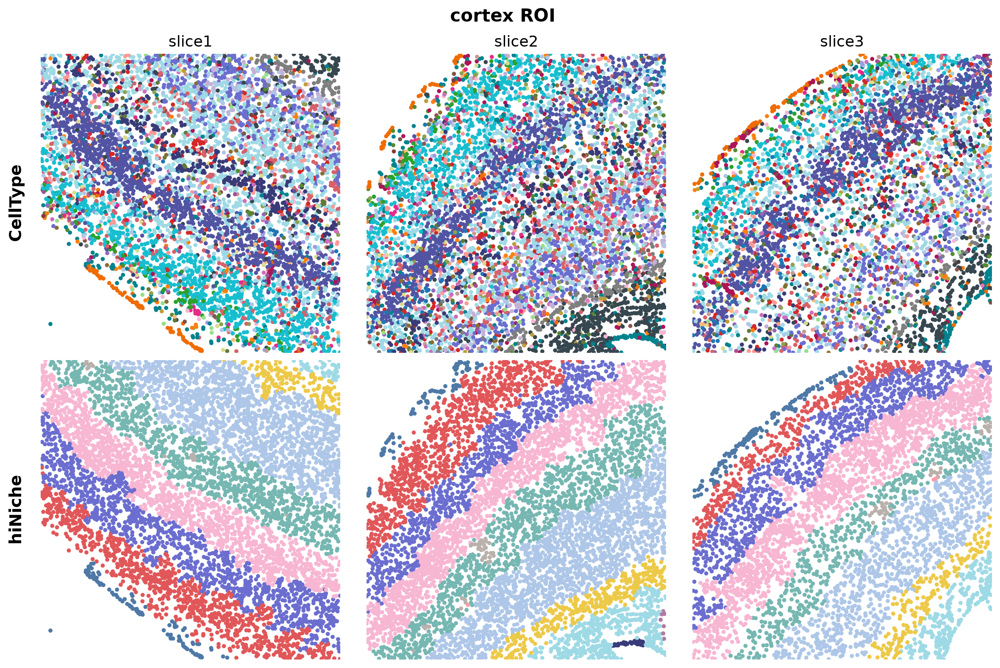

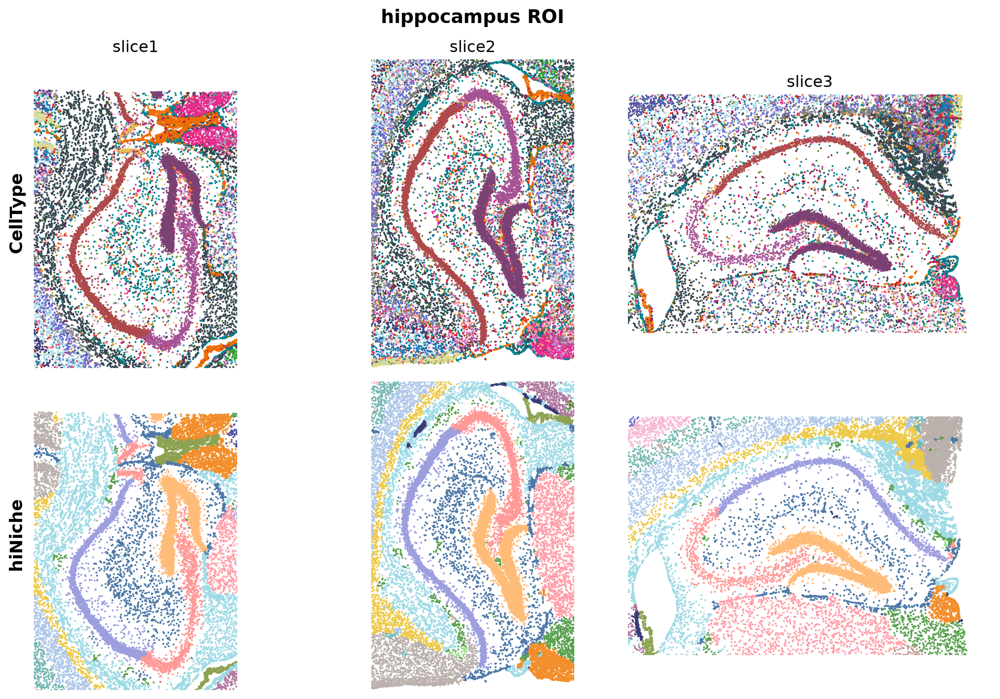

In [ ]:
# One ROI per slice (aligned with SLICES): [x_min, x_max, y_min, y_max] in full-resolution pixels
cortex_rois = [[4144+2000+2000, 9760+2000+2000, 10500+2000+2000, 16116+2000+2000],
               [4644-1000, 10260-1000, 2500+1000, 8116+1000],
               [2144+1000, 7760+1000, 3500-1000, 9116-1000]]
hippo_rois  = [[7344, 14854, 1700, 13116],
               [4344-500, 11854-500, 8700, 20116],
               [7700, 19116, 2844, 10354]]

roi_sets  = {"cortex": cortex_rois, "hippocampus": hippo_rois}   # one figure per ROI set
point_size =  {"cortex": 50, "hippocampus": 10} 
NICHE_KEY = "niche"              # "niche" (before merge) or "niche_merged" (after merge)
methods   = ["CellType", "hiNiche"]

# ---- Cell centers per slice: mean pixel coordinate of each cell's spots (after re-assignment) ----
def cell_centers(b):
    S = S_s2c_updated_list[b].coalesce()
    srow, scol = S.indices(); n_cell = S.size(1)
    sxy = torch.as_tensor(spatial_pixel_list[b], dtype=torch.float32)
    pos = torch.zeros((n_cell, 2)).index_add_(0, scol, sxy[srow])
    cnt = torch.zeros(n_cell).index_add_(0, scol, torch.ones_like(scol, dtype=torch.float32))
    return (pos / cnt.clamp(min=1).unsqueeze(1)).numpy(), cnt.numpy(), n_cell
centers = {b: cell_centers(b) for b in range(n_slice)}

def hiniche_labels(b, n_cell):
    """Niche cluster of each cell of slice b (via the niche's center cell); -1 = not a niche center."""
    lab = np.full(n_cell, -1, dtype=int)
    lab[np.asarray(active_niche_indices_list[b])] = np.asarray(clusters_id[NICHE_KEY])[slice_id["niche"].numpy() == b]
    return lab

def celltype_labels(b, n_cell):
    """Predicted cell type (argmax of the cell embedding) of each cell of slice b."""
    return np.asarray(celltypes)[F.softmax(emb_all["cell"][slice_id["cell"] == b], dim=1).argmax(1).cpu().numpy()]

label_getters = {
    "hiNiche":  hiniche_labels,
    "CellType": celltype_labels,
}

for roi_name, rois in roi_sets.items():
    fig, axes = plt.subplots(len(methods), n_slice,
                             figsize=(4 * n_slice, 4 * len(methods)), dpi=200, squeeze=False)
    for r, meth in enumerate(methods):
        for b in range(n_slice):
            ax = axes[r][b]
            cp, cc, n_cell = centers[b]
            lab = label_getters[meth](b, n_cell)
            x_min, x_max, y_min, y_max = map(int, rois[b])
            in_roi = (cp[:, 0] >= x_min) & (cp[:, 0] < x_max) & (cp[:, 1] >= y_min) & (cp[:, 1] < y_max)

            if meth == "CellType":                          # cell types: names -> celltype_color
                m = in_roi & (cc > 0)
                colors = [celltype_color.get(t, "#cccccc") for t in lab[m]]
            else:                                           # niche clusters: ids -> umap_color
                m = in_roi & (cc > 0) & (lab >= 0)
                colors = [umap_color[f"Cluster_{int(v) % 40}"] for v in lab[m]]

            ax.scatter(cp[m, 0], cp[m, 1], c=colors, s=point_size[roi_name], marker='.', linewidths=0, rasterized=True)
            ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
            ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
            if r == 0:
                ax.set_title(SLICES[b], fontsize=13)
            if b == 0:
                ax.text(-0.08, 0.5, meth, transform=ax.transAxes, rotation=90,
                        va="center", ha="center", fontsize=14, fontweight="bold")

    fig.suptitle(f"{roi_name} ROI", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"s_{roi_name}.pdf")
    plt.show()